# Etapa 1 — Coleta e organização de múltiplas capturas

## Variante B: reconstrução e comparação de vários objetos

O primeiro objeto é `pedra_cubica`. O notebook foi organizado para incluir outros objetos e várias capturas do mesmo objeto, por exemplo vídeos gravados com exposições, aberturas ou ISO diferentes. Cada vídeo é uma entrada independente em `DATASETS`, identificada por `object_name` e `capture_id`, e deve ter uma pasta de quadros própria. Selecione as entradas a processar em `ACTIVE_DATASET_IDS`. Os metadados registrados para cada vídeo são salvos em `informacoes_captura.txt` junto aos quadros e impressos durante o carregamento. As visualizações, tabelas e metadados derivados são salvos em `outputs/<object_name>/`; diretórios de resultados incluem `capture_id` e a quantidade real de quadros (por exemplo, `pedra_cubica_base_80quadros_etapa4`) para comparar execuções com diferentes amostragens.

**Dados da captura inicial:** vídeo `images/pedra_cubica/P1011579.MOV`; Olympus OM-D E-M5 Mark II; foco manual (MF); f/5.6; 1/125 s; ISO 800. Esses valores se aplicam somente a este vídeo; ao adicionar uma captura, registre suas configurações reais.

São extraídos até 80 quadros uniformemente distribuídos por vídeo. Recomenda-se cobrir o objeto em duas ou três alturas, com sobreposição suficiente entre vistas, e incluir uma referência de escala conhecida.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "extrair_imagens.py").is_file() and (ROOT / "t2" / "extrair_imagens.py").is_file():
    ROOT = ROOT / "t2"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from extrair_imagens import extrair_imagens

# Adicione uma entrada por vídeo/captura. Para novas condições de exposição do
# mesmo objeto, use o mesmo object_name, outro capture_id e outra pasta quadros_dir.
DATASETS = [
    {
        "capture_id": "pedra_cubica_base",
        "object_name": "pedra_cubica",
        "video_path": ROOT / "images" / "pedra_cubica" / "P1011579.MOV",
        # Mantém os 80 quadros já extraídos para o vídeo inicial.
        "quadros_dir": ROOT / "images" / "pedra_cubica",
        "camera": {
            "model": "Olympus OM-D E-M5 Mark II",
            "focus": "MF (manual)",
            "aperture": "f/5.6",
            "shutter_speed": "1/125 s",
            "iso": 800,
            "exposure_label": "captura base",
            # Preencha após medir o objeto; valores em mm e cm³.
            "expected_dimensions_mm": {"maior": None, "intermediaria": None, "menor": None},
            "expected_volume_cm3": None,
        },
        # Calibração independente para esta captura usando o grid de 5 mm.
        "grid_calibration": {
            "enabled": True,
            "frame_indices": None,  # None seleciona os sete quadros finais da captura.
            "grid_size": (5, 5),  # número de interseções; clique abrange 4 x 4 quadrados
            "square_size_m": 0.005,
        },
    },
    # Modelo para uma nova exposição do mesmo objeto:
    # {
    #     "capture_id": "pedra_cubica_iso1600",
    #     "object_name": "pedra_cubica",
    #     "video_path": ROOT / "images" / "pedra_cubica" / "captura_iso1600" / "video.mov",
    #     "quadros_dir": ROOT / "images" / "pedra_cubica" / "captura_iso1600" / "quadros",
    #     "camera": {"model": "Olympus OM-D E-M5 Mark II", "focus": "MF",
    #                "aperture": "f/5.6", "shutter_speed": "1/125 s",
    #                "iso": 1600, "exposure_label": "ISO 1600",
    #                "expected_dimensions_mm": {"maior": None, "intermediaria": None, "menor": None},
    #                "expected_volume_cm3": None},
    #     "grid_calibration": {"enabled": True, "frame_indices": None,
    #                          "grid_size": (5,5), "square_size_m": 0.005},
    # },
    # Modelo para outro objeto: copie a entrada acima, troque object_name,
    # capture_id, video_path, quadros_dir e os metadados da captura.
]

ACTIVE_DATASET_IDS = ["pedra_cubica_base"]
NUM_FRAMES = 80
REEXTRACT = False  # True para extrair novamente; False reutiliza quadros existentes.

datasets_by_id = {dataset["capture_id"]: dataset for dataset in DATASETS}
if len(datasets_by_id) != len(DATASETS):
    raise ValueError("Cada captura precisa de um capture_id único.")
selected_datasets = [datasets_by_id[capture_id] for capture_id in ACTIVE_DATASET_IDS]

for dataset in selected_datasets:
    video_path = Path(dataset["video_path"])
    quadros_dir = Path(dataset["quadros_dir"])
    quadros_dir.mkdir(parents=True, exist_ok=True)
    if not video_path.is_file():
        raise FileNotFoundError(f"Vídeo não encontrado para {dataset['capture_id']}: {video_path}")

    existing_quadros = sorted(quadros_dir.glob(f"quadro_*_de_{NUM_FRAMES:04d}_*.jpg"))
    if not existing_quadros and not REEXTRACT and NUM_FRAMES == 80:
        # Compatibilidade com quadros extraídos antes de incluir a contagem no nome.
        existing_quadros = sorted(quadros_dir.glob("frame_*.jpg"))
    if REEXTRACT or len(existing_quadros) < 2:
        frame_paths = extrair_imagens(video_path=video_path, output_dir=quadros_dir, num_frames=NUM_FRAMES)
    else:
        frame_paths = existing_quadros

    camera = dataset["camera"]
    info = [
        f"Identificador da captura: {dataset['capture_id']}",
        f"Objeto: {dataset['object_name']}",
        f"Vídeo: {video_path}",
        f"Câmera: {camera.get('model', 'não registrada')}",
        f"Foco: {camera.get('focus', 'não registrado')}",
        f"Abertura: {camera.get('aperture', 'não registrada')}",
        f"Velocidade do obturador: {camera.get('shutter_speed', 'não registrada')}",
        f"ISO: {camera.get('iso', 'not recorded')}",
        f"Identificação da exposição: {camera.get('exposure_label', 'não registrada')}",
        f"Quadros: {len(frame_paths)}",
    ]
    info_text = "\n".join(info) + "\n"
    info_path = quadros_dir / f"informacoes_captura_{dataset['capture_id']}_{len(frame_paths)}quadros.txt"
    info_path.write_text(info_text, encoding="utf-8")
    output_dir = ROOT / "outputs" / dataset["object_name"]
    output_dir.mkdir(parents=True, exist_ok=True)
    dataset["frame_tag"] = f"{len(frame_paths)}quadros"
    output_info_path = output_dir / f"informacoes_captura_{dataset['capture_id']}_{dataset['frame_tag']}.txt"
    output_info_path.write_text(info_text, encoding="utf-8")
    dataset["frame_paths"] = frame_paths
    dataset["info_path"] = info_path
    dataset["output_info_path"] = output_info_path
    print(f"\n=== {dataset['capture_id']} ===")
    print(info_path.read_text(encoding="utf-8"))
    print(f"Metadados copiados para: {output_info_path}")



=== pedra_cubica_base ===
Identificador da captura: pedra_cubica_base
Objeto: pedra_cubica
Vídeo: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\images\pedra_cubica\P1011579.MOV
Câmera: Olympus OM-D E-M5 Mark II
Foco: MF (manual)
Abertura: f/5.6
Velocidade do obturador: 1/125 s
ISO: 800
Identificação da exposição: captura base
Quadros: 80

Metadados copiados para: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\informacoes_captura_pedra_cubica_base_80quadros.txt


# Etapa 2 — Detectores e comparação de keypoints

Neste passo, SIFT, ORB e AKAZE detectam pontos de interesse no mesmo primeiro frame de cada captura. O painel mostra a imagem original e os 600 pontos mais fortes de cada detector; os totais e as figuras são salvos em `outputs/<object_name>/`.


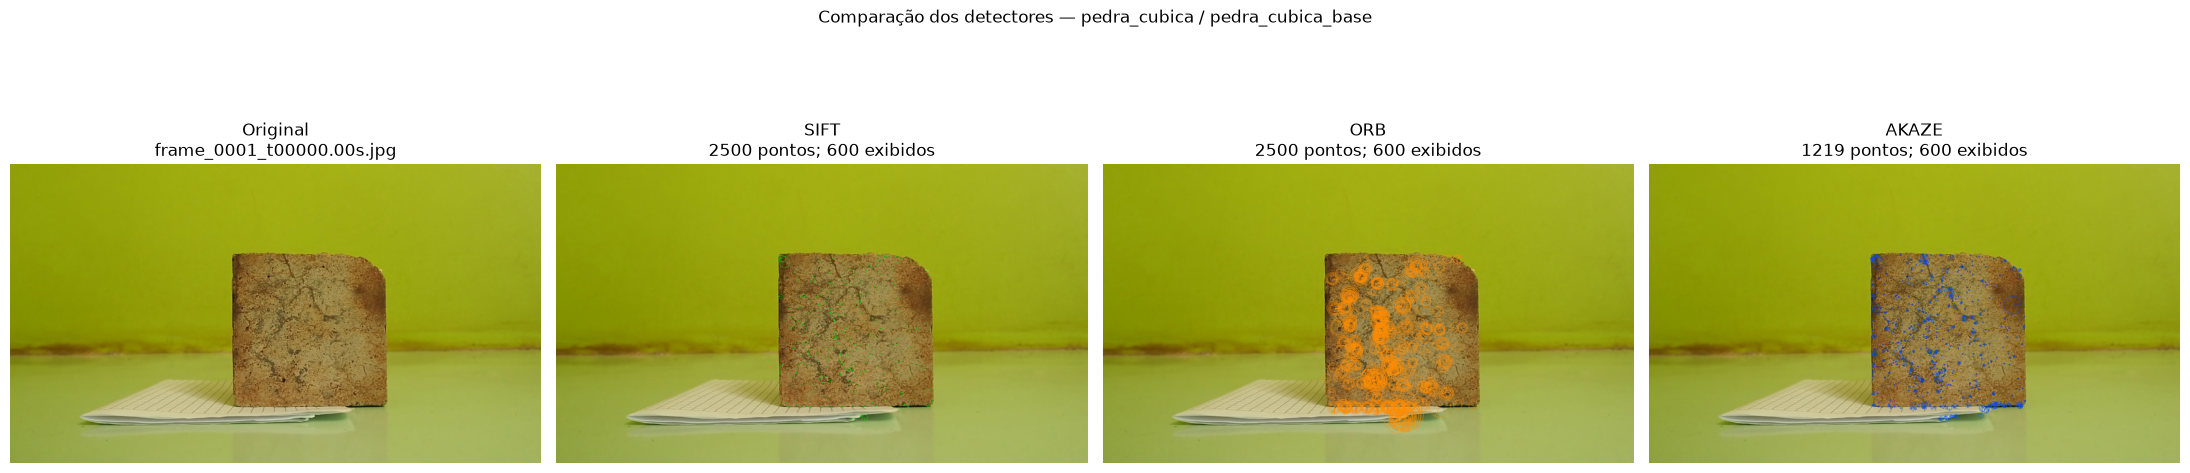

Comparação salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_comparacao_pontos_chave.png


In [2]:
# Visualização comparativa de keypoints no primeiro frame
import cv2
import matplotlib.pyplot as plt

from geometria_epipolar import detect_features

KEYPOINT_VISUALIZATIONS = {}
METHOD_COLORS_BGR = {"SIFT": (0, 220, 0), "ORB": (0, 140, 255), "AKAZE": (255, 80, 0)}

for dataset in selected_datasets:
    capture_id = dataset["capture_id"]
    KEYPOINT_OUTPUT_DIR = ROOT / "outputs" / dataset["object_name"]
    KEYPOINT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    first_image_path = dataset["frame_paths"][0]
    original = cv2.imread(str(first_image_path), cv2.IMREAD_COLOR)
    if original is None:
        raise FileNotFoundError(f"Não foi possível abrir o primeiro frame: {first_image_path}")

    fig, axes = plt.subplots(1, 4, figsize=(22, 6))
    axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Original\n{first_image_path.name}")
    KEYPOINT_VISUALIZATIONS[capture_id] = {}

    for ax, method in zip(axes[1:], ("SIFT", "ORB", "AKAZE")):
        features = detect_features(first_image_path, method, max_features=2500)
        strongest = sorted(features.keypoints, key=lambda point: point.response, reverse=True)[:600]
        rendered = cv2.drawKeypoints(
            original, strongest, None, color=METHOD_COLORS_BGR[method],
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
        )
        ax.imshow(cv2.cvtColor(rendered, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{method}\n{len(features.keypoints)} pontos; {len(strongest)} exibidos")
        individual_path = KEYPOINT_OUTPUT_DIR / f"{capture_id}_{len(dataset['frame_paths'])}quadros_pontos_chave_{method.lower()}.jpg"
        if not cv2.imwrite(str(individual_path), rendered, [cv2.IMWRITE_JPEG_QUALITY, 95]):
            raise RuntimeError(f"Não foi possível salvar: {individual_path}")
        KEYPOINT_VISUALIZATIONS[capture_id][method] = individual_path

    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"Comparação dos detectores — {dataset['object_name']} / {capture_id}")
    fig.tight_layout()
    comparison_path = KEYPOINT_OUTPUT_DIR / f"{capture_id}_{len(dataset['frame_paths'])}quadros_comparacao_pontos_chave.png"
    fig.savefig(comparison_path, dpi=160, bbox_inches="tight")
    KEYPOINT_VISUALIZATIONS[capture_id]["comparison"] = comparison_path
    plt.show()
    print(f"Comparação salva em: {comparison_path}")


## Preparação da câmera por captura

A calibração manual do papel quadriculado é feita uma vez no notebook `preparacao_calibracao.ipynb`, depois de extrair os quadros. A preparação usa os sete quadros finais por padrão. Esta célula da pipeline principal apenas carrega o arquivo de calibração salvo; não abre figuras para cliques e pode ser executada sem intervenção. Se a calibração estiver ausente ou os quadros/configuração tiverem mudado, execute primeiro o notebook de preparação.


In [3]:
import json
import numpy as np

for dataset in selected_datasets:
    config = dataset.get("grid_calibration", {})
    dataset["camera_matrix"] = None
    dataset["dist_coeffs"] = None
    if not config.get("enabled", False):
        print(f"{dataset['capture_id']}: calibração desabilitada; E/R/t/3D serão omitidos.")
        continue

    indices = config.get("frame_indices")
    if indices is None:
        indices = list(range(max(0, len(dataset["frame_paths"]) - 7), len(dataset["frame_paths"])))
    if len(indices) < 5 or any(i < 0 or i >= len(dataset["frame_paths"]) for i in indices):
        raise ValueError(f"Configure ao menos 5 índices válidos em grid_calibration para {dataset['capture_id']}.")
    calibration_paths = [dataset["frame_paths"][i] for i in indices]
    grid_size = tuple(config.get("grid_size", (5, 5)))
    square_size_m = float(config.get("square_size_m", 0.005))
    output_dir = ROOT / "outputs" / dataset["object_name"] / f"{dataset['capture_id']}_{dataset.get('frame_tag', 'quadros_desconhecidos')}_calibracao"
    cache_path = output_dir / f"calibracao_camera_{dataset.get('frame_tag', 'quadros_desconhecidos')}.npz"
    metadata_path = output_dir / f"calibracao_camera_{dataset.get('frame_tag', 'quadros_desconhecidos')}.json"
    settings = {"quadros": [p.name for p in calibration_paths], "grid_size": list(grid_size), "square_size_m": square_size_m}

    if not cache_path.is_file() or not metadata_path.is_file():
        raise FileNotFoundError(
            f"Calibração não preparada para {dataset['capture_id']}. Execute preparacao_calibracao.ipynb primeiro."
        )
    old_settings = json.loads(metadata_path.read_text(encoding="utf-8")).get("settings")
    if old_settings != settings:
        raise RuntimeError(
            f"Frames/configuração mudaram para {dataset['capture_id']}. Execute preparacao_calibracao.ipynb novamente."
        )
    with np.load(cache_path) as stored:
        result = {
            "camera_matrix": stored["camera_matrix"],
            "dist_coeffs": stored["dist_coeffs"],
            "rms_px": float(stored["rms_px"]),
            "per_view_rms_px": stored["per_view_rms_px"].tolist(),
            "image_size": tuple(stored["image_size"]),
            "image_points": [row for row in stored["image_points"]],
            "image_paths": calibration_paths,
            "overlays": [],
        }
    dataset["camera_matrix"] = result["camera_matrix"]
    dataset["dist_coeffs"] = result["dist_coeffs"]
    dataset["grid_calibration_data"] = result
    dataset["calibration_rms_px"] = result["rms_px"]
    print(f"{dataset['capture_id']} | RMS de reprojeção: {result['rms_px']:.3f} px | calibração carregada: {cache_path}")


pedra_cubica_base | RMS de reprojeção: 0.940 px | calibração carregada: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_calibracao\calibracao_camera_80quadros.npz


# Etapa 3 — Emparelhamento e geometria epipolar

Para cada par vizinho de quadros, o fluxo é:

1. **BFMatcher:** compara descritores SIFT com distância L2 e descritores ORB/AKAZE com distância Hamming.
2. **Ratio test de Lowe:** aceita a melhor correspondência quando sua distância é suficientemente menor que a segunda melhor (`ratio=0.75`). O `CROSS_CHECK` opcional aplica o mesmo teste no sentido inverso e mantém apenas pares mutuamente consistentes.
3. **Matriz fundamental `F`:** estima a geometria epipolar sem calibração usando RANSAC. Os inliers são as correspondências compatíveis com esse modelo; o notebook os mostra e pode desenhar as linhas epipolares correspondentes.
4. **Matriz essencial `E` e pose:** quando a matriz intrínseca calibrada `K` é fornecida, corrige os pontos pela distorção da lente, estima `E` com RANSAC e chama `recoverPose` para obter a rotação `R` e a translação `t` entre as duas câmeras.
5. **Triangulação inicial:** usa as correspondências da pose e as matrizes de projeção para calcular pontos 3D positivos à frente das duas câmeras. A escala de `t` é unitária e a nuvem resultante é relativa, não métrica; a referência física de escala será aplicada mais adiante.

Para evitar um gráfico 3D vazio, a escolha do par é feita separadamente: as imagens de correspondências e linhas epipolares usam o par com mais inliers de `F`; a nuvem 3D usa, entre os pares que produziram pontos triangulados válidos, aquele com mais pontos. O notebook imprime e salva o índice desse par geométrico.

`F` pode ser calculada sem `K`. Antes desta etapa, o notebook tenta calibrar cada captura a partir de uma região do papel quadriculado selecionada manualmente em vários do vídeo. A matriz `K` e a distorção resultantes são específicas de cada captura e alimentam `E`, `R`, `t` e a triangulação. Verifique os overlays das interseções detectadas e o erro de reprojeção; um erro alto ou um papel ondulado indica uma calibração apenas aproximada. O modelo da câmera e os valores de abertura, obturador e ISO não determinam `K`.

**Avaliação do papel quadriculado desta captura:** o grid está visível em todos os quadros extraídos e aparece em vários ângulos, mas nos quadros observados a folha está ondulada/sobreposta em algumas partes e o objeto cobre muitas interseções. Por isso, ela não é um plano rígido e suficientemente visível para uma calibração intrínseca confiável; não devemos calcular `K` a partir destes do vídeo. O espaçamento nominal de 5 mm ainda pode servir como referência aproximada de escala, desde que se use uma região plana e se considere a perspectiva. Para obter `K` e a distorção, capture separadamente um checkerboard/ChArUco plano em pelo menos várias poses inclinadas, com a mesma câmera, lente, resolução e foco. A detecção de um grid simples exigiria localizar e associar as mesmas interseções manualmente ou com um detector próprio; `findChessboardCorners` não o interpreta automaticamente como um tabuleiro alternado.

O relatório inclui também o deslocamento mediano dos matches inliers entre quadros vizinhos. Pares com deslocamento abaixo de 2 px em pelo menos dois detectores são marcados como candidatos quase duplicados; esse limiar é um diagnóstico conservador, não uma medida direta da sobreposição percentual.


In [4]:
import csv
import time
import numpy as np

import importlib
import geometria_epipolar
geometria_epipolar = importlib.reload(geometria_epipolar)
analyze_sequence = geometria_epipolar.analyze_sequence

CROSS_CHECK = False  # True ativa verificação mútua, além do ratio test de Lowe.
NEAR_DUPLICATE_THRESHOLD_PX = 2.0
ANALYSES = {}
comparison_rows = []

for dataset in selected_datasets:
    print(f"\nAnalisando {dataset['object_name']} / {dataset['capture_id']} ...")
    start = time.perf_counter()
    analysis = analyze_sequence(
        dataset["frame_paths"],
        methods=("SIFT", "ORB", "AKAZE"),
        max_features=2500,
        max_gap=1,
        ratio=0.75,
        ransac_threshold_px=1.5,
        camera_matrix=dataset["camera_matrix"],
        dist_coeffs=dataset["dist_coeffs"],
        cross_check=CROSS_CHECK,
    )
    elapsed = time.perf_counter() - start
    ANALYSES[dataset["capture_id"]] = analysis
    print(f"Pares avaliados: {analysis['pair_count']} | duração: {elapsed:.1f} s")
    for method, data in analysis["methods"].items():
        summary = data["summary"]
        row = {
            "object_name": dataset["object_name"],
            "capture_id": dataset["capture_id"],
            "exposure_label": dataset["camera"].get("exposure_label", "not recorded"),
            "aperture": dataset["camera"].get("aperture", "not recorded"),
            "shutter_speed": dataset["camera"].get("shutter_speed", "not recorded"),
            "iso": dataset["camera"].get("iso", "not recorded"),
            "method": method,
            "cross_check": CROSS_CHECK,
            "mean_keypoints": summary["mean_keypoints"],
            "median_ratio_matches": summary["median_ratio_matches"],
            "median_matches_after_cross_check": summary["median_matches"],
            "median_f_inliers": summary["median_f_inliers"],
            "valid_f_pairs": summary["valid_f_pairs"],
            "median_f_inlier_ratio": summary["median_f_inlier_ratio"],
            "median_sampson_px": summary["median_sampson_px"],
            "median_inlier_displacement_px": summary["median_inlier_displacement_px"],
            "valid_essential_pairs": summary["valid_essential_pairs"],
            "median_essential_inliers": summary["median_essential_inliers"],
            "median_pose_inliers": summary["median_pose_inliers"],
            "median_triangulated_points": summary["median_triangulated_points"],
            "analysis_seconds": elapsed,
            "calibration_rms_px": dataset.get("calibration_rms_px"),
        }
        comparison_rows.append(row)
        print(
            f"{method:<6} | kp {summary['mean_keypoints']:.1f} | Lowe {summary['median_ratio_matches']:.1f} | "
            f"matches finais {summary['median_matches']:.1f} | F inliers {summary['median_f_inliers']:.1f} | "
            f"F pares {summary['valid_f_pairs']} | movimento mediano {summary['median_inlier_displacement_px']:.2f} px | "
            f"pares com E {summary['valid_essential_pairs']} | "
            f"pontos 3D medianos {summary['median_triangulated_points']}"
        )

    # Registra o deslocamento entre pares e sinaliza movimentos muito pequenos quando ao menos
    # dois descritores concordam. Isso ajuda a identificar quadros consecutivos redundantes do vídeo.
    pair_motion = {}
    spacing_rows = []
    for method, data in analysis["methods"].items():
        for pair_result in data["pairs"]:
            i, j = pair_result["i"], pair_result["j"]
            displacement = pair_result["median_inlier_displacement_px"]
            pair_motion.setdefault((i, j), []).append(displacement)
            spacing_rows.append({
                "object_name": dataset["object_name"],
                "capture_id": dataset["capture_id"],
                "frame_a": dataset["frame_paths"][i].name,
                "frame_b": dataset["frame_paths"][j].name,
                "method": method,
                "f_inliers": pair_result["fundamental_inliers"],
                "median_inlier_displacement_px": displacement,
            })
    for (i, j), values in pair_motion.items():
        measured = [value for value in values if value is not None]
        near_duplicate = sum(value < NEAR_DUPLICATE_THRESHOLD_PX for value in measured) >= 2
        for row in spacing_rows:
            if row["frame_a"] == dataset["frame_paths"][i].name and row["frame_b"] == dataset["frame_paths"][j].name:
                row["near_duplicate_candidate"] = near_duplicate
    output_dir = ROOT / "outputs" / dataset["object_name"]
    output_dir.mkdir(parents=True, exist_ok=True)
    spacing_path = output_dir / f"{dataset['capture_id']}_{dataset.get('frame_tag', 'quadros_desconhecidos')}_diagnostico_deslocamento.csv"
    with spacing_path.open("w", newline="", encoding="utf-8-sig") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=list(spacing_rows[0]))
        writer.writeheader()
        writer.writerows(spacing_rows)
    candidates = [
        (i, j, float(np.median([v for v in values if v is not None])))
        for (i, j), values in pair_motion.items()
        if sum(v is not None and v < NEAR_DUPLICATE_THRESHOLD_PX for v in values) >= 2
    ]
    print(f"Pares candidatos a quase duplicados (<{NEAR_DUPLICATE_THRESHOLD_PX:g} px): {candidates}")
    print(f"Diagnóstico frame a frame salvo em: {spacing_path}")

for object_name in sorted({row["object_name"] for row in comparison_rows}):
    object_rows = [row for row in comparison_rows if row["object_name"] == object_name]
    comparison_path = ROOT / "outputs" / object_name / f"comparacao_capturas_{'_'.join(str(len(d['frame_paths'])) for d in selected_datasets)}_quadros.csv"
    comparison_path.parent.mkdir(parents=True, exist_ok=True)
    with comparison_path.open("w", newline="", encoding="utf-8-sig") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=list(object_rows[0]))
        writer.writeheader()
        writer.writerows(object_rows)
    print(f"\nComparação de {object_name} salva em: {comparison_path}")



Analisando pedra_cubica / pedra_cubica_base ...
Pares avaliados: 79 | duração: 122.4 s
SIFT   | kp 1496.0 | Lowe 336.0 | matches finais 336.0 | F inliers 275.0 | F pares 79 | movimento mediano 89.59 px | pares com E 79 | pontos 3D medianos 145.0
ORB    | kp 2097.8 | Lowe 384.0 | matches finais 384.0 | F inliers 279.0 | F pares 79 | movimento mediano 92.84 px | pares com E 79 | pontos 3D medianos 156.0
AKAZE  | kp 780.3 | Lowe 213.0 | matches finais 213.0 | F inliers 156.0 | F pares 78 | movimento mediano 129.60 px | pares com E 78 | pontos 3D medianos 70.0
Pares candidatos a quase duplicados (<2 px): [(0, 1, 1.4511922597885132), (15, 16, 1.5694903135299683), (25, 26, 0.9387845993041992), (26, 27, 0.19050122797489166), (27, 28, 0.24542543292045593), (45, 46, 1.3567014932632446), (46, 47, 0.4672092795372009)]
Diagnóstico frame a frame salvo em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_diagnostico_deslocamento.csv

Comparação de pedra_cu

## Comparação dos inliers RANSAC: SIFT, ORB e AKAZE

Como em T1, registramos todos os pares por método, agora usando os inliers de `F` estimada por RANSAC. A tabela inclui matches após Lowe, número e taxa de inliers, cobertura espacial e erros de Sampson. O gráfico compara a série completa e as medianas; o painel final mostra os três métodos no mesmo par de quadros para uma comparação visual justa.


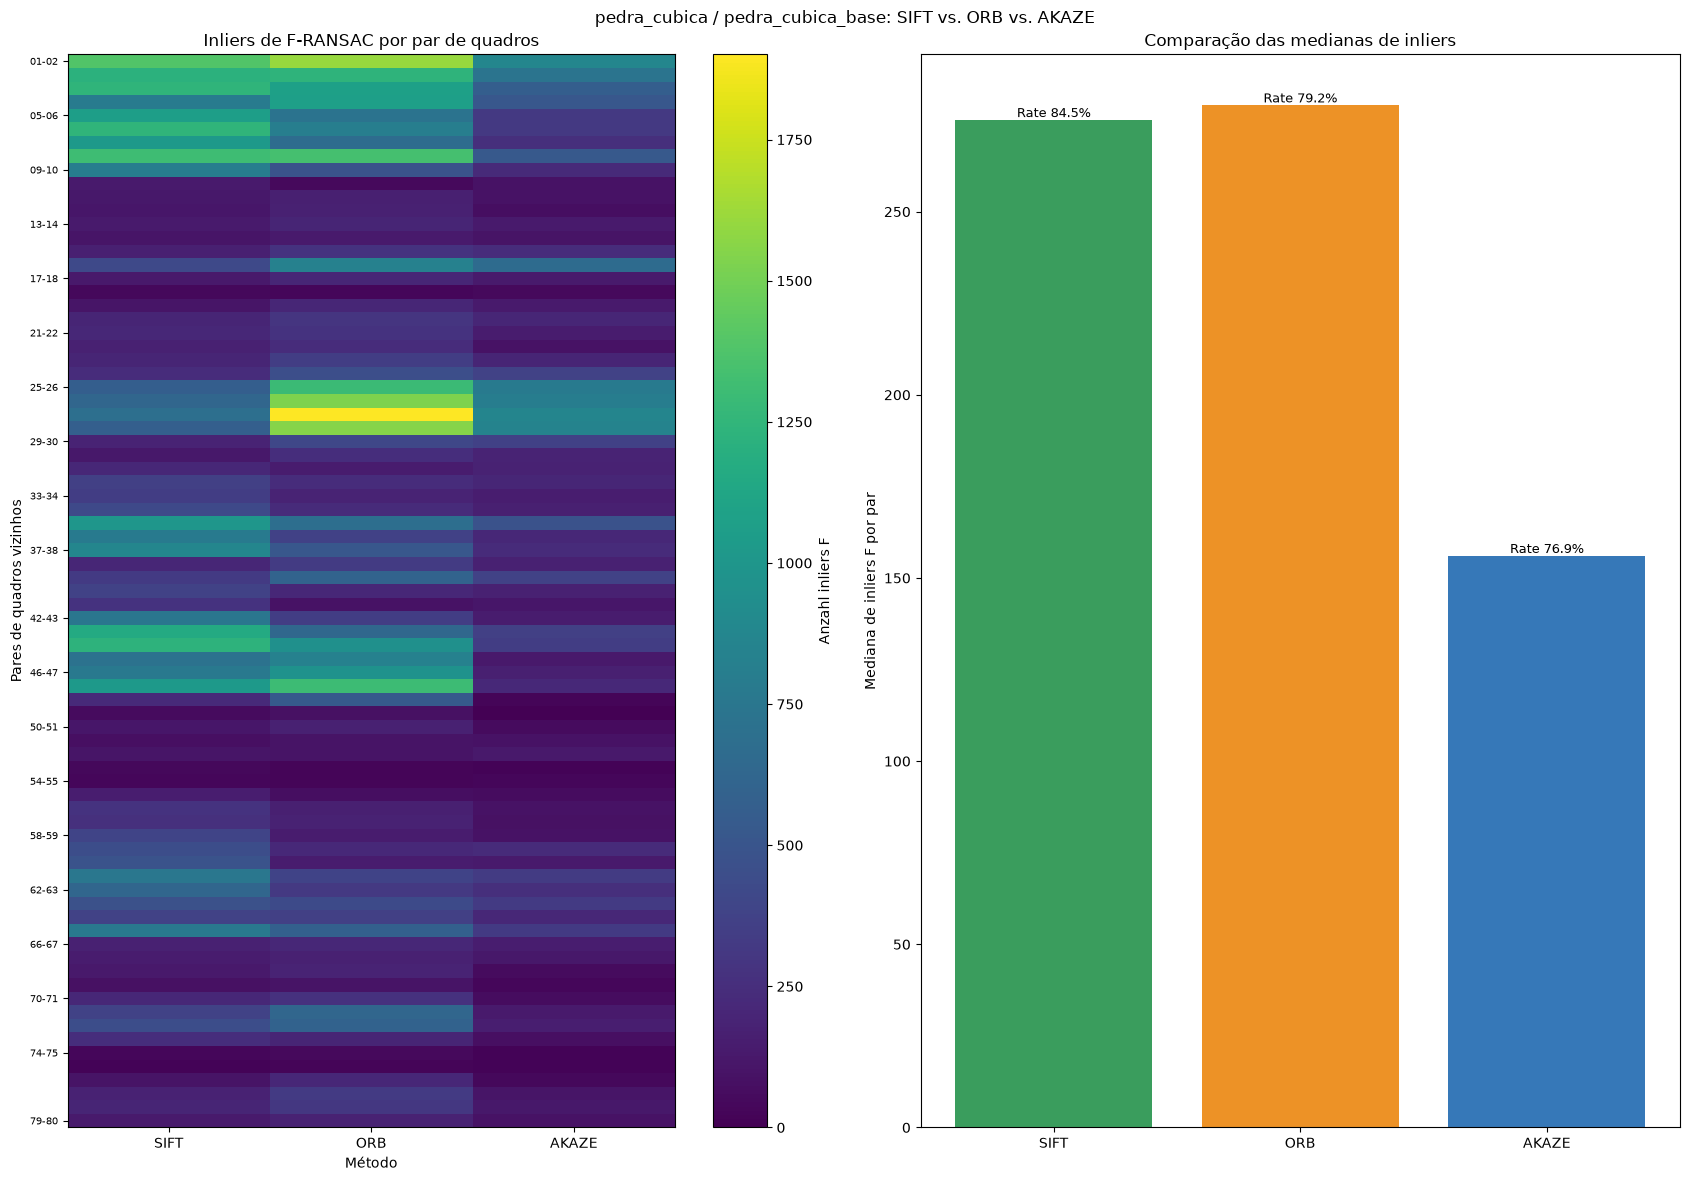

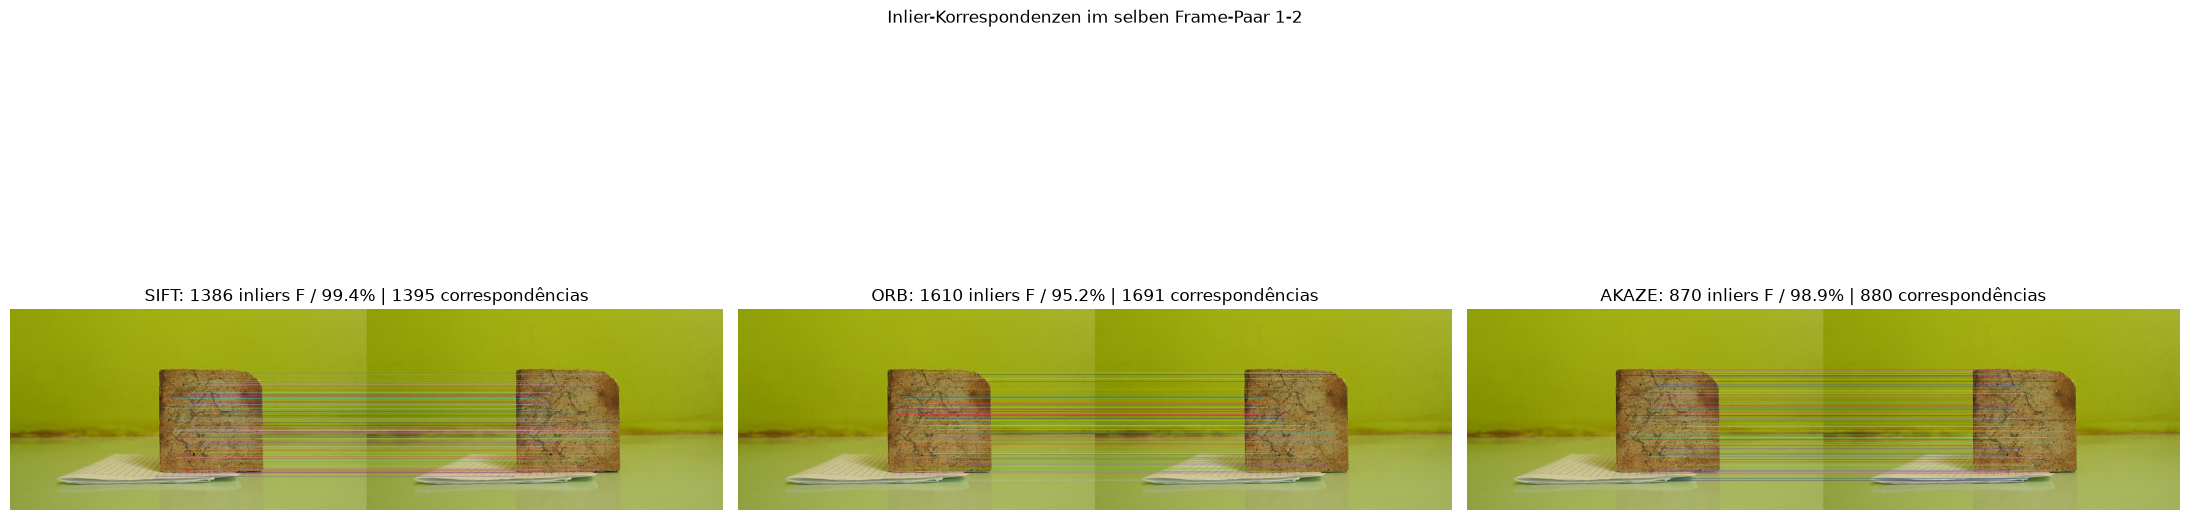


pedra_cubica_base: Inlier-Tabelle: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_comparacao_inliers.csv
Inlier-Heatmap und Medianvergleich: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_grafico_inliers.png
Gleicher Frame-Paar für alle drei Methoden: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_correspondencias_inliers.png


In [5]:
from pathlib import Path
import csv
import cv2
import matplotlib.pyplot as plt
import numpy as np
from geometria_epipolar import draw_inlier_matches

INLIER_COMPARISONS = {}
METHOD_ORDER = ("SIFT", "ORB", "AKAZE")

for dataset in selected_datasets:
    capture_id = dataset["capture_id"]
    analysis = ANALYSES[capture_id]
    output_dir = ROOT / "outputs" / dataset["object_name"]
    output_dir.mkdir(parents=True, exist_ok=True)
    records = []
    for method in METHOD_ORDER:
        for pair_result in analysis["methods"][method]["pairs"]:
            matches = pair_result["match_count"]
            inliers = pair_result["fundamental_inliers"]
            records.append({
                "object_name": dataset["object_name"], "capture_id": capture_id, "method": method,
                "frame_a": dataset["frame_paths"][pair_result["i"]].name,
                "frame_b": dataset["frame_paths"][pair_result["j"]].name,
                "ratio_test_matches": pair_result["ratio_match_count"], "matches_after_cross_check": matches,
                "F_inliers": inliers,
                "inlier_rate": inliers / matches if matches else 0.0,
                "sampson_mean_px": pair_result["mean_sampson_px"],
                "sampson_median_px": pair_result["median_sampson_px"],
                "sampson_p90_px": pair_result["p90_sampson_px"],
                "inlier_coverage": pair_result["inlier_coverage"],
                "F_estimated": pair_result["fundamental"] is not None,
            })

    csv_path = output_dir / f"{capture_id}_{len(dataset['frame_paths'])}quadros_comparacao_inliers.csv"
    with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows(records)

    pair_keys = sorted({(p["i"], p["j"]) for method in METHOD_ORDER for p in analysis["methods"][method]["pairs"]})
    pair_labels = [f"{i+1:02d}-{j+1:02d}" for i, j in pair_keys]
    inlier_matrix = np.zeros((len(pair_keys), len(METHOD_ORDER)), dtype=float)
    rate_matrix = np.zeros_like(inlier_matrix)
    lookup = {(method, p["i"], p["j"]): p for method in METHOD_ORDER for p in analysis["methods"][method]["pairs"]}
    for row_i, (i, j) in enumerate(pair_keys):
        for col_i, method in enumerate(METHOD_ORDER):
            pair_result = lookup[(method, i, j)]
            inlier_matrix[row_i, col_i] = pair_result["fundamental_inliers"]
            rate_matrix[row_i, col_i] = pair_result["fundamental_inlier_ratio"]

    common_pairs = [pair for pair in pair_keys if all(lookup[(m, *pair)]["fundamental"] is not None for m in METHOD_ORDER)]
    best_pair = max(common_pairs or pair_keys, key=lambda pair: sum(lookup[(m, *pair)]["fundamental_inliers"] for m in METHOD_ORDER))
    fig, axes = plt.subplots(1, 2, figsize=(17, max(6, min(12, len(pair_keys) * 0.16))))
    heat = axes[0].imshow(inlier_matrix, aspect="auto", interpolation="nearest", cmap="viridis")
    axes[0].set_title("Inliers de F-RANSAC por par de quadros")
    axes[0].set_xlabel("Método")
    axes[0].set_ylabel("Pares de quadros vizinhos")
    axes[0].set_xticks(range(len(METHOD_ORDER)), METHOD_ORDER)
    if len(pair_keys) <= 40:
        axes[0].set_yticks(range(len(pair_keys)), pair_labels, fontsize=7)
    else:
        tick_idx = np.unique(np.linspace(0, len(pair_keys)-1, 20).astype(int))
        axes[0].set_yticks(tick_idx, [pair_labels[k] for k in tick_idx], fontsize=7)
    fig.colorbar(heat, ax=axes[0], label="Anzahl inliers F")
    med_inliers = [float(np.median(inlier_matrix[:, k])) for k in range(len(METHOD_ORDER))]
    med_rates = [float(np.median(rate_matrix[:, k])) for k in range(len(METHOD_ORDER))]
    x = np.arange(len(METHOD_ORDER))
    bars = axes[1].bar(x, med_inliers, color=("#3a9d5d", "#ed9226", "#3678b8"))
    axes[1].set_xticks(x, METHOD_ORDER)
    axes[1].set_ylabel("Mediana de inliers F por par")
    axes[1].set_title("Comparação das medianas de inliers")
    for bar, rate in zip(bars, med_rates):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"Rate {rate:.1%}", ha="center", va="bottom", fontsize=9)
    fig.suptitle(f"{dataset['object_name']} / {capture_id}: SIFT vs. ORB vs. AKAZE")
    fig.tight_layout()
    chart_path = output_dir / f"{capture_id}_{len(dataset['frame_paths'])}quadros_grafico_inliers.png"
    fig.savefig(chart_path, dpi=160, bbox_inches="tight")
    plt.show()

    # Comparação visual no mesmo par, escolhido pela soma de inliers F.
    match_fig, match_axes = plt.subplots(1, 3, figsize=(22, 8))
    for ax, method in zip(match_axes, METHOD_ORDER):
        pair_result = lookup[(method, *best_pair)]
        if pair_result["fundamental"] is not None:
            rendered = draw_inlier_matches(analysis, method, pair=best_pair, max_matches=80)
            ax.imshow(cv2.cvtColor(rendered, cv2.COLOR_BGR2RGB))
            ax.set_title(f"{method}: {pair_result['fundamental_inliers']} inliers F / "
                         f"{pair_result['fundamental_inlier_ratio']:.1%} | {pair_result['match_count']} correspondências")
        else:
            ax.text(0.5, 0.5, f"{method}: F não estimada\npara este par de quadros", ha="center", va="center")
            ax.set_title(method)
        ax.axis("off")
    match_fig.suptitle(f"Inlier-Korrespondenzen im selben Frame-Paar {best_pair[0]+1}-{best_pair[1]+1}")
    match_fig.tight_layout()
    match_path = output_dir / f"{capture_id}_{len(dataset['frame_paths'])}quadros_correspondencias_inliers.png"
    match_fig.savefig(match_path, dpi=160, bbox_inches="tight")
    plt.show()

    INLIER_COMPARISONS[capture_id] = {"csv": csv_path, "chart": chart_path, "matches": match_path, "best_pair": best_pair}
    print(f"\n{capture_id}: Inlier-Tabelle: {csv_path}")
    print(f"Inlier-Heatmap und Medianvergleich: {chart_path}")
    print(f"Gleicher Frame-Paar für alle drei Methoden: {match_path}")


## Inspeção visual dos inliers e linhas epipolares

Para cada método, o notebook escolhe o par válido com mais inliers. Assim cada método é mostrado em seu melhor par estimado, que pode diferir entre SIFT, ORB e AKAZE. As figuras são salvas em `outputs/<object_name>/`.


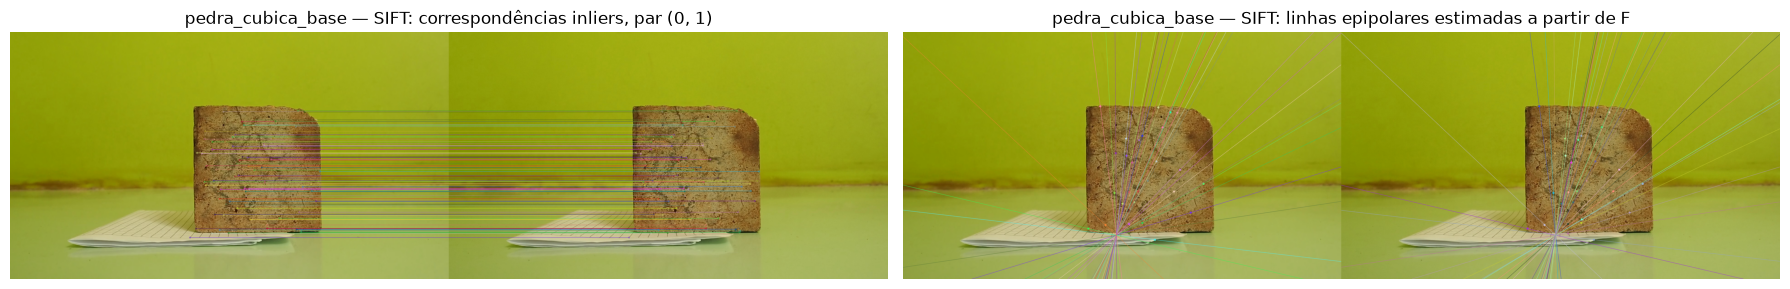

Visualização salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_linhas_epipolares_sift.png
Par geométrico selecionado para SIFT: (42, 43); 1098 pontos 3D válidos.
Par (42, 43) — inliers E: 1098; inliers de pose: 1098
R (rotação da câmera 1 para a câmera 2):
 [[ 0.97396133 -0.00921844 -0.22652672]
 [ 0.0092211   0.99995694 -0.00104643]
 [ 0.22652661 -0.00106964  0.97400439]]
t (direção de translação, escala unitária):
 [ 0.99521006 -0.00614682 -0.09756614]
Centro da câmera 2 no referencial da câmera 1 (-R.T @ t):
 [-0.9471381   0.01521648  0.32046509]
Pontos 3D iniciais após teste de profundidade positiva: 1098


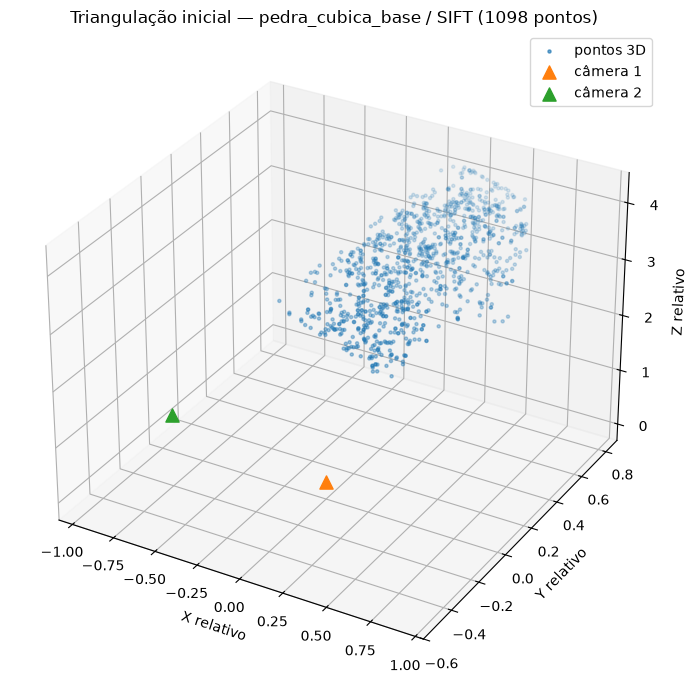

Geometria salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_geometria_sift_par_42_43.npz
Visualização 3D salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_triangulacao_sift.png


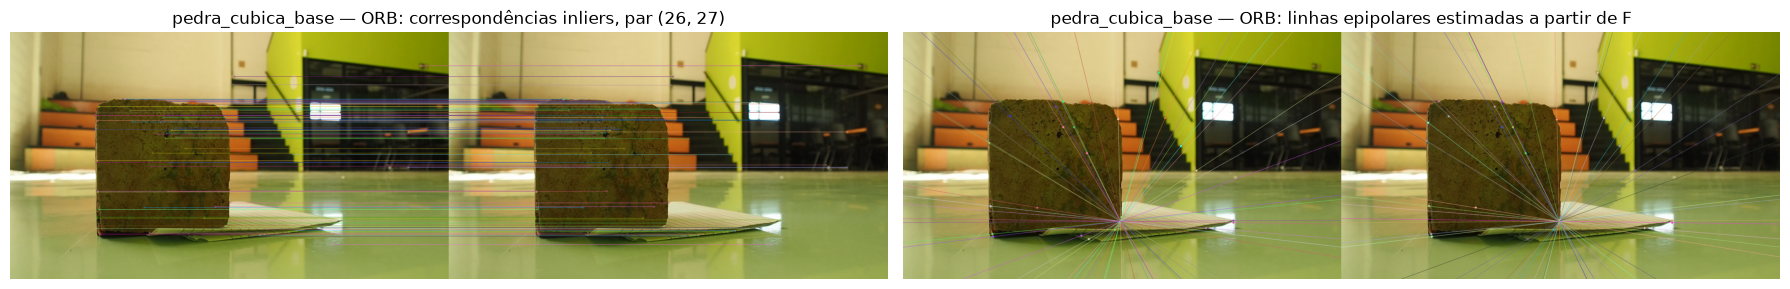

Visualização salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_linhas_epipolares_orb.png
Par geométrico selecionado para ORB: (44, 45); 788 pontos 3D válidos.
Par (44, 45) — inliers E: 788; inliers de pose: 788
R (rotação da câmera 1 para a câmera 2):
 [[ 0.99655924 -0.02358124 -0.07945814]
 [ 0.02706194  0.99870775  0.04301712]
 [ 0.07834107 -0.0450194   0.9959096 ]]
t (direção de translação, escala unitária):
 [ 0.93671193 -0.34965163 -0.01773409]
Centro da câmera 2 no referencial da câmera 1 (-R.T @ t):
 [-0.92263737  0.37049025  0.10713195]
Pontos 3D iniciais após teste de profundidade positiva: 788


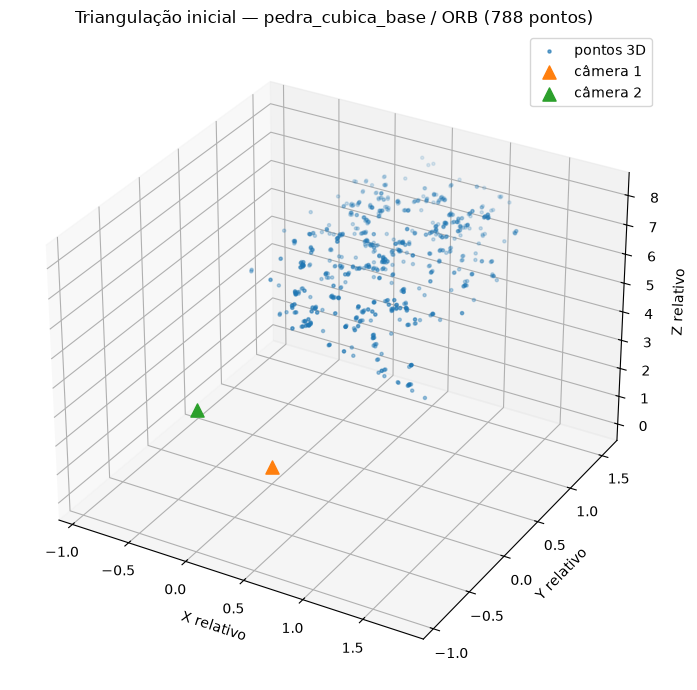

Geometria salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_geometria_orb_par_44_45.npz
Visualização 3D salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_triangulacao_orb.png


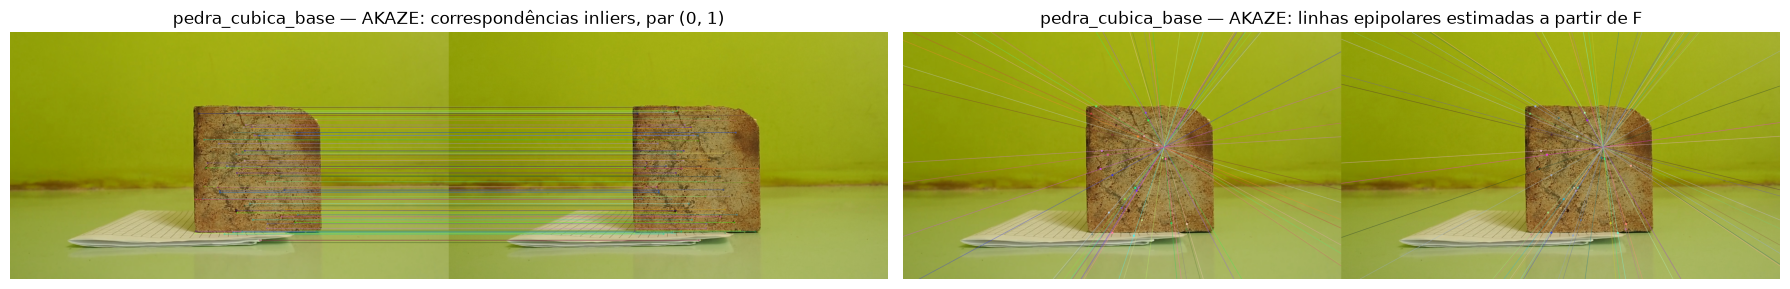

Visualização salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_linhas_epipolares_akaze.png
Par geométrico selecionado para AKAZE: (43, 44); 342 pontos 3D válidos.
Par (43, 44) — inliers E: 342; inliers de pose: 342
R (rotação da câmera 1 para a câmera 2):
 [[ 0.9769207  -0.00706774 -0.21348534]
 [ 0.00418821  0.9998941  -0.01393746]
 [ 0.21356124  0.01272167  0.97684684]]
t (direção de translação, escala unitária):
 [0.9975142  0.06232951 0.03287034]
Centro da câmera 2 no referencial da câmera 1 (-R.T @ t):
 [-0.98177315 -0.0556909   0.18171409]
Pontos 3D iniciais após teste de profundidade positiva: 342


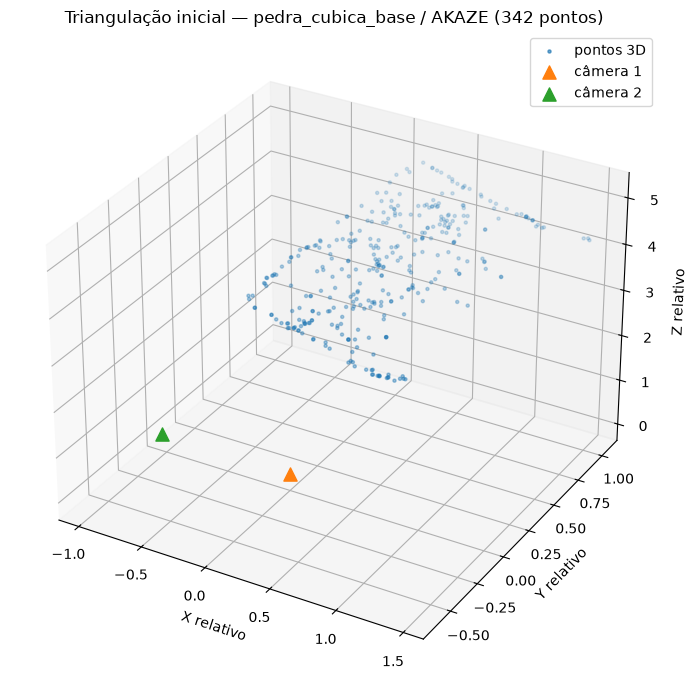

Geometria salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_geometria_akaze_par_43_44.npz
Visualização 3D salva em: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_triangulacao_akaze.png


In [6]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

from geometria_epipolar import draw_epipolar_lines, draw_inlier_matches

for dataset in selected_datasets:
    capture_id = dataset["capture_id"]
    analysis = ANALYSES[capture_id]
    for method, data in analysis["methods"].items():
        valid_pairs = [pair_result for pair_result in data["pairs"] if pair_result["fundamental"] is not None]
        if not valid_pairs:
            print(f"{capture_id} / {method}: nenhum par permitiu estimar F")
            continue
        best_epipolar = max(valid_pairs, key=lambda pair_result: pair_result["fundamental_inliers"])
        pair = (best_epipolar["i"], best_epipolar["j"])
        fig, axes = plt.subplots(1, 2, figsize=(18, 7))
        axes[0].imshow(cv2.cvtColor(draw_inlier_matches(analysis, method, pair=pair), cv2.COLOR_BGR2RGB))
        axes[0].set_title(f"{capture_id} — {method}: correspondências inliers, par {pair}")
        axes[1].imshow(cv2.cvtColor(draw_epipolar_lines(analysis, method, pair=pair), cv2.COLOR_BGR2RGB))
        axes[1].set_title(f"{capture_id} — {method}: linhas epipolares estimadas a partir de F")
        for ax in axes:
            ax.axis("off")
        fig.tight_layout()
        output_dir = ROOT / "outputs" / dataset["object_name"]
        output_dir.mkdir(parents=True, exist_ok=True)
        visual_path = output_dir / f"{capture_id}_{len(dataset['frame_paths'])}quadros_linhas_epipolares_{method.lower()}.png"
        fig.savefig(visual_path, dpi=160, bbox_inches="tight")
        plt.show()
        print(f"Visualização salva em: {visual_path}")

        triangulated_pairs = [
            pair_result for pair_result in valid_pairs
            if pair_result["rotation"] is not None
            and pair_result["triangulated_points"] is not None
            and pair_result["triangulated_count"] > 0
        ]
        if not triangulated_pairs:
            print(f"{capture_id} / {method}: nenhum par produziu pontos 3D válidos.")
            continue
        best_geometry = max(
            triangulated_pairs,
            key=lambda pair_result: (pair_result["triangulated_count"], pair_result["fundamental_inliers"]),
        )
        geometry_pair = (best_geometry["i"], best_geometry["j"])
        print(f"Par geométrico selecionado para {method}: {geometry_pair}; "
              f"{best_geometry['triangulated_count']} pontos 3D válidos.")

        rotation = best_geometry["rotation"]
        translation = best_geometry["translation"].ravel()
        camera_center_2 = best_geometry["camera_center_2"]
        points_3d = best_geometry["triangulated_points"]
        print(f"Par {geometry_pair} — inliers E: {best_geometry['essential_inliers']}; inliers de pose: {best_geometry['pose_inliers']}")
        print("R (rotação da câmera 1 para a câmera 2):\n", rotation)
        print("t (direção de translação, escala unitária):\n", translation)
        print("Centro da câmera 2 no referencial da câmera 1 (-R.T @ t):\n", camera_center_2)
        print(f"Pontos 3D iniciais após teste de profundidade positiva: {len(points_3d)}")

        geometry_path = output_dir / f"{capture_id}_{len(dataset['frame_paths'])}quadros_geometria_{method.lower()}_par_{geometry_pair[0]}_{geometry_pair[1]}.npz"
        np.savez_compressed(
            geometry_path,
            F=best_geometry["fundamental"], E=best_geometry["essential"], R=rotation,
            t=translation, camera_center_2=camera_center_2,
            points_3d=points_3d,
        )
        cloud_fig = plt.figure(figsize=(8, 7))
        ax = cloud_fig.add_subplot(111, projection="3d")
        ax.scatter(points_3d[:, 0], points_3d[:, 1], points_3d[:, 2], s=5, alpha=0.65, label="pontos 3D")
        ax.scatter([0], [0], [0], marker="^", s=90, label="câmera 1")
        ax.scatter(*camera_center_2, marker="^", s=90, label="câmera 2")
        ax.set_title(f"Triangulação inicial — {capture_id} / {method} ({len(points_3d)} pontos)")
        ax.set_xlabel("X relativo")
        ax.set_ylabel("Y relativo")
        ax.set_zlabel("Z relativo")
        ax.legend()
        cloud_fig.tight_layout()
        cloud_path = output_dir / f"{capture_id}_{len(dataset['frame_paths'])}quadros_triangulacao_{method.lower()}.png"
        cloud_fig.savefig(cloud_path, dpi=160, bbox_inches="tight")
        plt.show()
        print(f"Geometria salva em: {geometry_path}")
        print(f"Visualização 3D salva em: {cloud_path}")


# Etapa 4 — SfM, escala métrica, MVS e textura

Esta etapa executa SfM no COLMAP, estima poses e nuvem esparsa, calcula profundidade por PatchMatch MVS e produz duas nuvens densas (consistência geométrica e fotométrica). A nuvem geométrica alimenta a malha Poisson e a textura. A escala métrica vem das interseções do grid de 5 mm identificadas na calibração desta captura.

São salvos os modelos, nuvens, malhas, textura, render e comparação lado a lado em `outputs/<objeto>/<captura>_<N>quadros_etapa4/`. O processamento precisa do COLMAP com CUDA para o PatchMatch e de `open3d`. Esta etapa gera artefatos; as métricas de qualidade e erros em relação às medidas reais são calculados separadamente na Etapa 5.


In [7]:
import importlib
import etapa4_colmap
importlib.reload(etapa4_colmap)
from etapa4_colmap import run_etapa4_colmap

# Caminho do COLMAP: None se estiver no PATH (Windows/Linux); caso contrário,
# informe COLMAP.bat (Windows) ou o executável colmap (Linux).
COLMAP_EXECUTABLE = r"C:\Apps\COLMAP\COLMAP.bat"
RUN_ETAPA4 = True

if RUN_ETAPA4:
    ETAPA4_REPORTS = {}
    for dataset in selected_datasets:
        if dataset.get("grid_calibration_data") is None:
            raise RuntimeError(
                f"Calibração do grid ausente para {dataset['capture_id']}; execute a célula de calibração antes da Etapa 4."
            )
        grid_config = dataset["grid_calibration"]
        etapa4_dir = ROOT / "outputs" / dataset["object_name"] / f"{dataset['capture_id']}_{dataset.get('frame_tag', 'quadros_desconhecidos')}_etapa4"
        report = run_etapa4_colmap(
            dataset["frame_paths"], output_dir=etapa4_dir,
            colmap_executable=COLMAP_EXECUTABLE,
            calibration=dataset["grid_calibration_data"],
            scale_view_index=int(grid_config.get("scale_view_index", 0)),
            grid_size=tuple(grid_config["grid_size"]),
            square_size_m=float(grid_config["square_size_m"]),
            max_image_size=1600, sequential_overlap=10, gpu_index="-1",
        )
        ETAPA4_REPORTS[dataset["capture_id"]] = report
        print(f"Etapa 4 concluída para {dataset['capture_id']}: {report}")
        photo_render = cv2.imread(report["side_by_side"])
        if photo_render is not None:
            plt.figure(figsize=(18, 7)); plt.imshow(cv2.cvtColor(photo_render, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


RuntimeError: COLMAP command 'sequential_matcher' failed with exit code 3221226505. See log: C:\01b_TUM\26_WiSe_Forschung\CompVision\t2\outputs\pedra_cubica\pedra_cubica_base_80quadros_etapa4\registro_colmap_80quadros.log

# Etapa 5 — Avaliação da reconstrução

Esta etapa lê os artefatos métricos da Etapa 4 e calcula erro médio e mediano de reprojeção, números de pontos esparsos e densos, densidade aproximada em pontos/m², erros absoluto e relativo das dimensões em mm e, se a malha for fechada, o erro do volume. Preencha as referências reais em `camera.expected_dimensions_mm` e `camera.expected_volume_cm3` na Etapa 1. O relatório JSON e a comparação foto/render ficam associados ao número de quadros da execução.


In [ ]:
from etapa5_avaliacao import avaliar_etapa5

RUN_ETAPA5 = True
if RUN_ETAPA5:
    ETAPA5_REPORTS = {}
    for dataset in selected_datasets:
        report4 = ETAPA4_REPORTS[dataset["capture_id"]]
        output_dir = Path(report4["sparse_text_model"]).parent.parent
        report5 = avaliar_etapa5(
            report4, output_dir=output_dir,
            expected_dimensions_mm=dataset["camera"].get("expected_dimensions_mm"),
            expected_volume_cm3=dataset["camera"].get("expected_volume_cm3"),
        )
        ETAPA5_REPORTS[dataset["capture_id"]] = report5
        print(f"Etapa 5 — {dataset['capture_id']}:\n{json.dumps(report5, indent=2, ensure_ascii=False)}")
